In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

In [2]:
from benchmark_func import params_search, print_summary, run_benchmark, show_graph

from algorithms.baseline import UserBasedCF
from algorithms.implicit_als import ImplicitALS
from utils.data_load import load_dataset, make_subset, save_df, split_train_test_by_time


c:\Users\shsas\miniconda3\envs\recsys-benchmark\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
DATA_PATH = "../data/raw/ratings.csv"

DATA_TRAIN_1M_PATH = "../data/processed/train_1M.csv"
DATA_TEST_1M_PATH = "../data/processed/test_1M.csv"

N_RUNS = 3

In [4]:
df = load_dataset(path=DATA_PATH)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32000204 entries, 0 to 32000203
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(3)
memory usage: 976.6 MB


In [5]:
df.head()

,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [6]:
try:
    train = load_dataset(DATA_TRAIN_1M_PATH)
    test = load_dataset(DATA_TEST_1M_PATH)
except FileNotFoundError:
    subset = make_subset(df=df, n_ratings=1_000_000)
    train, test = split_train_test_by_time(subset)
    save_df(df=train, path=DATA_TRAIN_1M_PATH)
    save_df(df=test, path=DATA_TEST_1M_PATH)

print(train.shape, test.shape)

(800500, 4) (200086, 4)


In [7]:
train.describe()

,userId,movieId,rating,timestamp
count,800500.000000,800500.000000,800500.000000,8.005000e+05
mean,98646.270209,25929.397535,3.572943,1.266412e+09
std,58418.514135,46291.101800,1.062505,2.560993e+08
min,141.000000,1.000000,0.500000,8.243892e+08
25%,47598.000000,1209.000000,3.000000,1.031770e+09
50%,98500.000000,3081.000000,4.000000,1.254978e+09
75%,150270.000000,33166.000000,4.000000,1.498865e+09
max,200935.000000,290263.000000,5.000000,1.696168e+09


In [8]:
test.describe()

,userId,movieId,rating,timestamp
count,200086.00000,200086.000000,200086.000000,2.000860e+05
mean,98647.76692,41712.255165,3.481840,1.306111e+09
std,58423.08884,64574.528694,1.059222,2.653764e+08
min,141.00000,1.000000,0.500000,8.271370e+08
25%,47598.00000,1517.000000,3.000000,1.070599e+09
50%,98484.00000,4487.000000,3.500000,1.335776e+09
75%,150291.00000,65802.000000,4.000000,1.546649e+09
max,200935.00000,292141.000000,5.000000,1.697157e+09


In [9]:
def model_factory():
    return UserBasedCF(top_k=20)

results = run_benchmark(model_factory, train, test, n_runs=N_RUNS)

print_summary(results)

[timer] Обучение UserBasedCF: 2.496 сек.
[timer] Выдача рекомендаций UserBasedCF: 5.514 сек.
[timer] Обучение UserBasedCF: 2.481 сек.
[timer] Выдача рекомендаций UserBasedCF: 5.551 сек.
[timer] Обучение UserBasedCF: 2.435 сек.
[timer] Выдача рекомендаций UserBasedCF: 5.501 сек.
UserBasedCF
Количество пользователей: 6,314
Количество объектов: 21,388
Количество оценок в train: 800,500
Разреженность матрицы оценок: 0.5928%
Размер матрицы схожестей: 0.15 ГБ
Среднее train_time 2.4705517292022705
Среднее pred_time 5.522090752919515
Средний recall 0.02803864435793312
Средний ndcg 0.02464104623284104
Количество ненулевых оценок в тестовой матрице: 194,773
Количество релевантных оценок в тестовой матрице (>=3.5): 120,582
Пользователей с ненулевыми оценками в тестовой матрице: 6,313
Пользователей с релевантными оценками в тестовой матрице: 6,215


Подбор гиперпараметров для базовой модели `UserBasedCF`

In [10]:
df = params_search(
    model_factory=lambda **kw: UserBasedCF(**kw),
    train=train,
    test=test,
    params={"top_k": [5, 10, 15, 20, 30, 50]},
    n_runs=N_RUNS,
)

[timer] Обучение UserBasedCF: 2.434 сек.
[timer] Выдача рекомендаций UserBasedCF: 2.608 сек.
[timer] Обучение UserBasedCF: 2.434 сек.
[timer] Выдача рекомендаций UserBasedCF: 2.585 сек.
[timer] Обучение UserBasedCF: 2.450 сек.
[timer] Выдача рекомендаций UserBasedCF: 2.604 сек.
[timer] Обучение UserBasedCF: 2.778 сек.
[timer] Выдача рекомендаций UserBasedCF: 3.418 сек.
[timer] Обучение UserBasedCF: 2.404 сек.
[timer] Выдача рекомендаций UserBasedCF: 3.627 сек.
[timer] Обучение UserBasedCF: 2.615 сек.
[timer] Выдача рекомендаций UserBasedCF: 3.708 сек.
[timer] Обучение UserBasedCF: 2.480 сек.
[timer] Выдача рекомендаций UserBasedCF: 4.530 сек.
[timer] Обучение UserBasedCF: 2.431 сек.
[timer] Выдача рекомендаций UserBasedCF: 4.508 сек.
[timer] Обучение UserBasedCF: 2.505 сек.
[timer] Выдача рекомендаций UserBasedCF: 4.706 сек.
[timer] Обучение UserBasedCF: 2.466 сек.
[timer] Выдача рекомендаций UserBasedCF: 5.487 сек.
[timer] Обучение UserBasedCF: 2.441 сек.
[timer] Выдача рекомендаций U

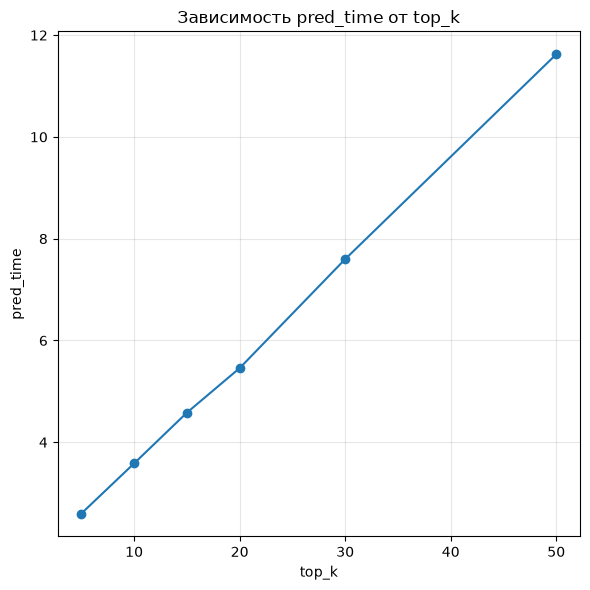

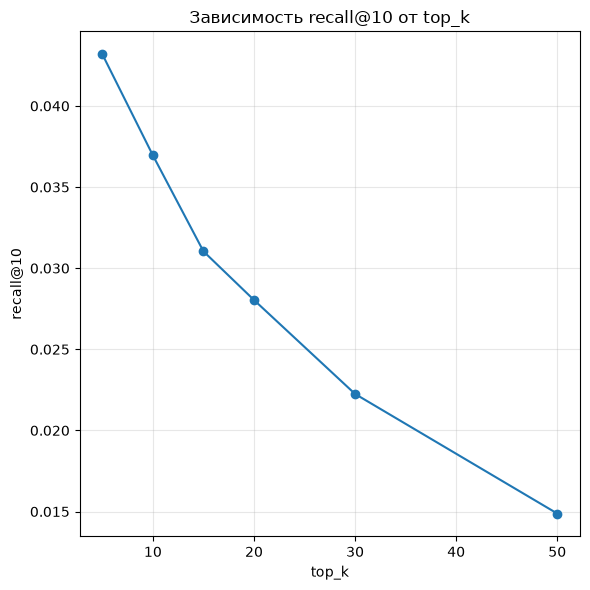

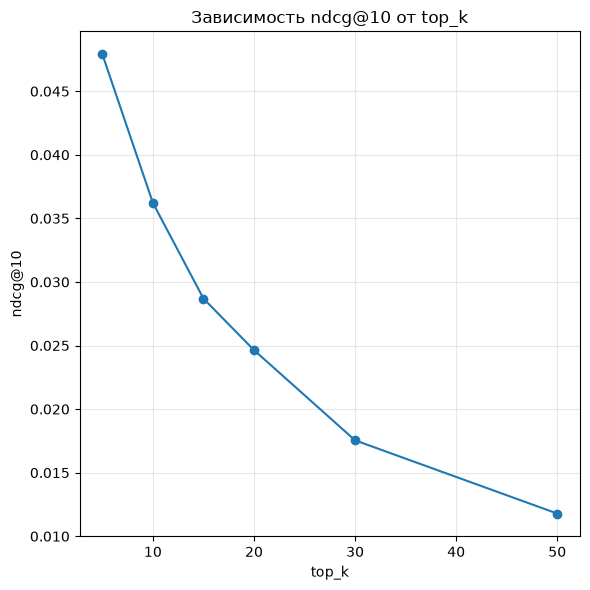

In [11]:
show_graph(
    results_df=df,
    params=["top_k"],
    metrics=["pred_time", "recall@10", "ndcg@10"],
    save_dir="graphs/UserBasedCF",
)

In [12]:
def model_factory():
    return UserBasedCF(top_k=5)

results = run_benchmark(model_factory, train, test, n_runs=N_RUNS)

print_summary(results)

[timer] Обучение UserBasedCF: 2.419 сек.
[timer] Выдача рекомендаций UserBasedCF: 2.637 сек.
[timer] Обучение UserBasedCF: 2.408 сек.
[timer] Выдача рекомендаций UserBasedCF: 2.575 сек.
[timer] Обучение UserBasedCF: 2.494 сек.
[timer] Выдача рекомендаций UserBasedCF: 2.629 сек.
UserBasedCF
Количество пользователей: 6,314
Количество объектов: 21,388
Количество оценок в train: 800,500
Разреженность матрицы оценок: 0.5928%
Размер матрицы схожестей: 0.15 ГБ
Среднее train_time 2.4404940605163574
Среднее pred_time 2.613671859105428
Средний recall 0.04318276171931504
Средний ndcg 0.04790683376035909
Количество ненулевых оценок в тестовой матрице: 194,773
Количество релевантных оценок в тестовой матрице (>=3.5): 120,582
Пользователей с ненулевыми оценками в тестовой матрице: 6,313
Пользователей с релевантными оценками в тестовой матрице: 6,215


Таким образом, лучший `top_k=5`:

- при `top_k=5` - самые похожие пользователи, у которых много общих фильмов;
- при `top_k=100` - все, у кого есть хоть 1 общий, включая почти случайных;
- меньше - лучше, потому что сигнал чище.

memory-based CF деградирует при добавлении соседей, потому что нет достаточного числа действительно похожих пользователей.

In [13]:
def model_factory():
    return ImplicitALS(factors=64, iterations=20, regularization=0.05, alpha=40.0)

results = run_benchmark(model_factory, train, test, n_runs=N_RUNS)

print_summary(results)

c:\Users\shsas\miniconda3\envs\recsys-benchmark\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 16 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


[timer] Обучение implicit ALS: 1.068 сек.
[timer] Выдача рекомендаций implicit ALS: 0.818 сек.
[timer] Обучение implicit ALS: 1.013 сек.
[timer] Выдача рекомендаций implicit ALS: 0.802 сек.
[timer] Обучение implicit ALS: 1.015 сек.
[timer] Выдача рекомендаций implicit ALS: 0.834 сек.
Модель: implicit ALS (factors=64, iterations=20, regularization=0.05, alpha=40.0)
Количество пользователей: 6314
Количество объектов: 21388
Количество оценок в train: 800500
Разреженность матрицы взаимодействий: 0.5928%
Среднее train_time 1.0319074789683025
Среднее pred_time 0.817793051401774
Средний recall 0.02946396294258574
Средний ndcg 0.041783239274723084


In [14]:
df = params_search(
    model_factory=lambda **kw: ImplicitALS(**kw),
    train=train,
    test=test,
    params={
        "factors": [32, 64, 128],
        "iterations": [10, 15, 20],
        "regularization": [0.05, 0.1, 0.2],
        "alpha": [40.0],
    },
    n_runs=N_RUNS,
)

[timer] Обучение implicit ALS: 0.484 сек.
[timer] Выдача рекомендаций implicit ALS: 0.895 сек.
[timer] Обучение implicit ALS: 0.496 сек.
[timer] Выдача рекомендаций implicit ALS: 0.808 сек.
[timer] Обучение implicit ALS: 0.501 сек.
[timer] Выдача рекомендаций implicit ALS: 1.000 сек.
[timer] Обучение implicit ALS: 0.486 сек.
[timer] Выдача рекомендаций implicit ALS: 0.990 сек.
[timer] Обучение implicit ALS: 0.484 сек.
[timer] Выдача рекомендаций implicit ALS: 0.979 сек.
[timer] Обучение implicit ALS: 0.483 сек.
[timer] Выдача рекомендаций implicit ALS: 0.984 сек.
[timer] Обучение implicit ALS: 0.480 сек.
[timer] Выдача рекомендаций implicit ALS: 0.986 сек.
[timer] Обучение implicit ALS: 0.480 сек.
[timer] Выдача рекомендаций implicit ALS: 0.971 сек.
[timer] Обучение implicit ALS: 0.488 сек.
[timer] Выдача рекомендаций implicit ALS: 0.978 сек.
[timer] Обучение implicit ALS: 0.697 сек.
[timer] Выдача рекомендаций implicit ALS: 0.969 сек.
[timer] Обучение implicit ALS: 0.692 сек.
[timer] 

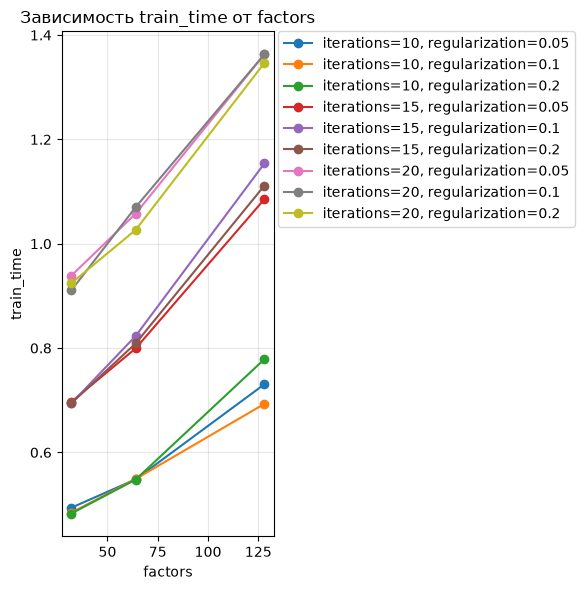

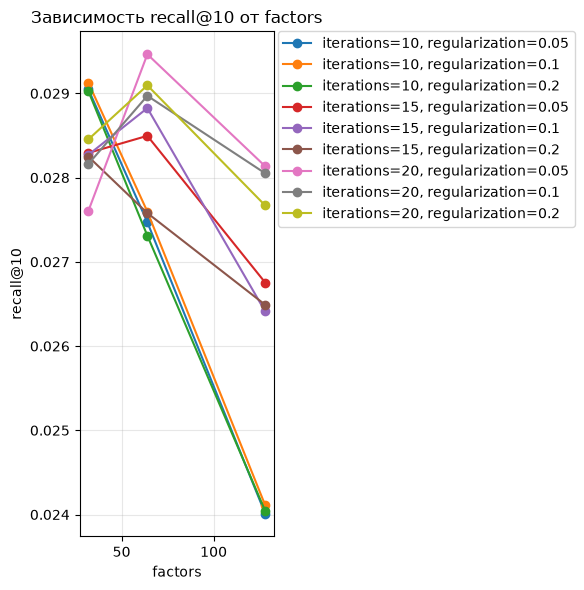

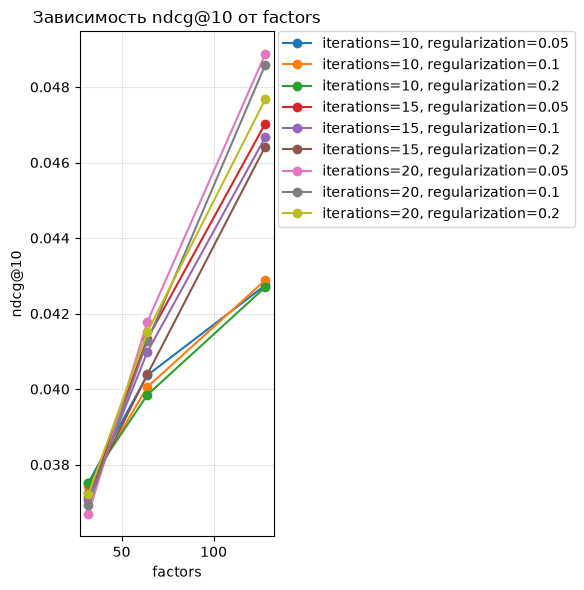

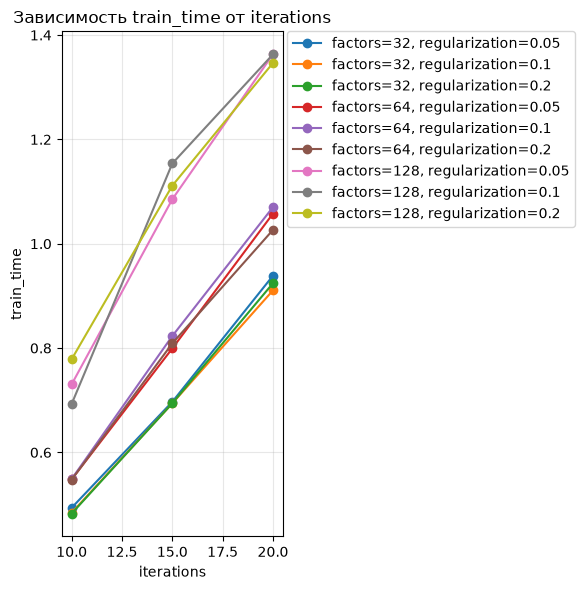

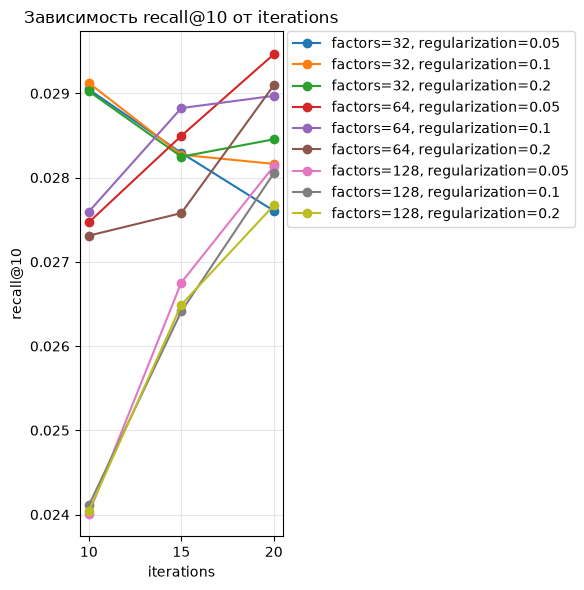

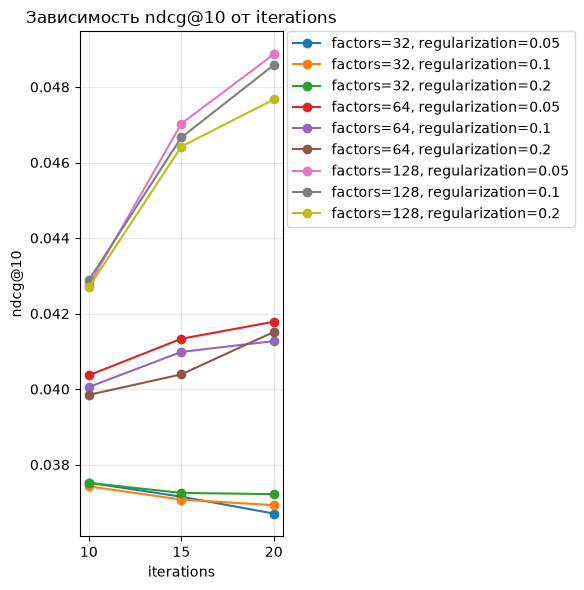

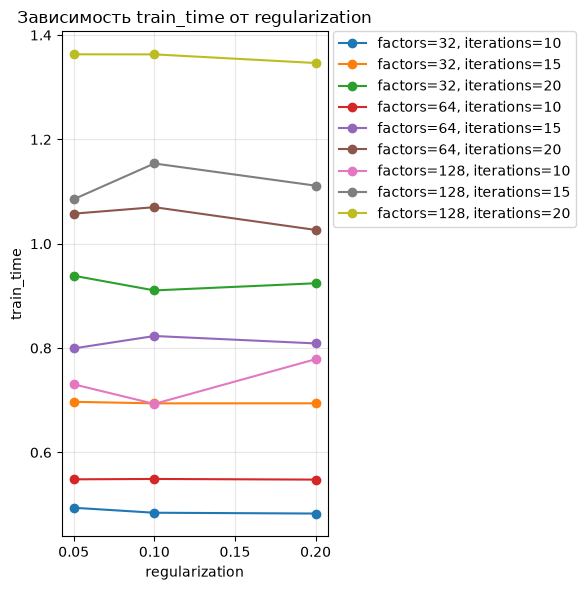

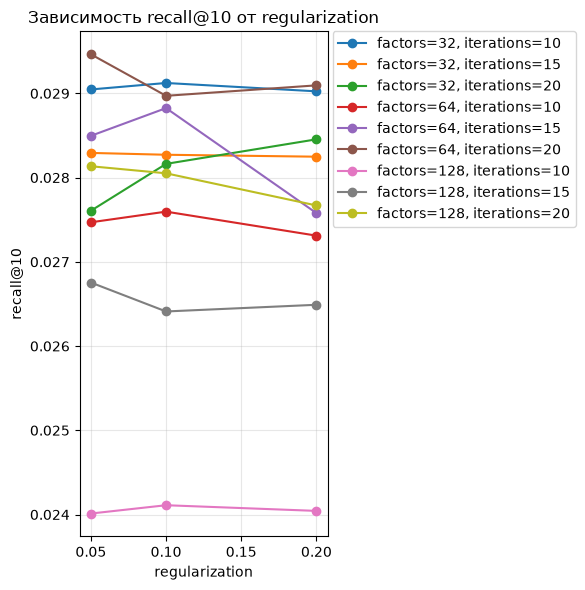

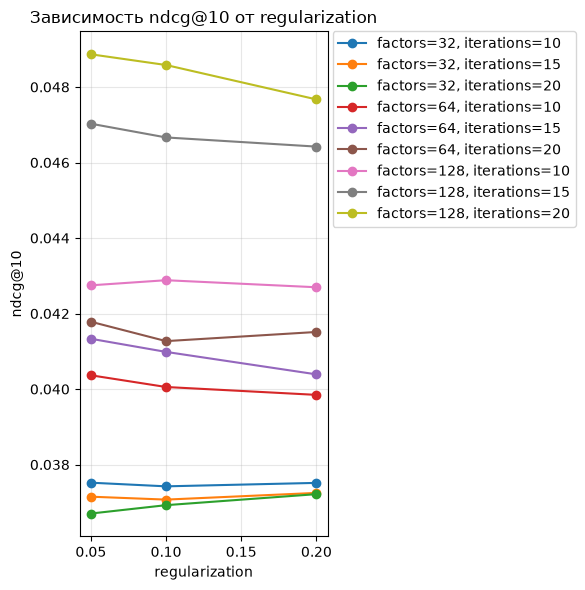

In [16]:
show_graph(
    results_df=df,
    params=["factors", "iterations", "regularization"],
    metrics=["train_time", "recall@10", "ndcg@10"],
    save_dir="graphs/implicitALS",
)

Оптимальный выбор параметров: `factors=128`, `iterations=30`, `regularization=0.05`.

На графике зависимости `NDCG@10` от `factors` видно, что 128 факторов дают большой прирост качества по сравнению с 64 и 32. Для задач ранжирования (рекомендаций) прирост NDCG наиболее важно для бизнеса.

Для 128 факторов график `NDCG@10` от `iterations` показывает, что модель демонстрирует лучшие метрики при высоком значении `iterations`.

Графики однозначно показывают, что минимальная регуляризация (0.05) дает лучший `NDCG`. Большая регуляризация мешает модели запоминать сложные паттерны.

`pred_time` при 128 факторах составляет примерно 1.2 сек, что медленнее, чем при 64. Но если это обучение модели происходит редко, можно выбрать качество вместо скорости. 

In [ ]:
def model_factory():
    return ImplicitALS(factors=128, iterations=30, regularization=0.05, alpha=40.0)

results = run_benchmark(model_factory, train, test, n_runs=3)

print_summary(results)

[timer] Обучение implicit ALS: 2.237 сек.
[timer] Выдача рекомендаций implicit ALS: 0.891 сек.
Модель: implicit ALS (factors=128, iterations=30, regularization=0.05, alpha=40.0)
Количество пользователей: 6314
Количество объектов: 21388
Количество оценок в train: 800500
Разреженность матрицы взаимодействий: 0.5928%
Среднее train_time 2.2367753982543945
Среднее pred_time 0.8914229869842529
Средний recall 0.02962416915434525
Средний ndcg 0.05017942622796065


| Алгоритм | Параметры | Train time, сек | Predict time, сек | Recall@10 | NDCG@10 |
|---|---|---|---|---|---|
| UserBasedCF | top_k=5 | 2.441 | 2.614 | 0.0432 | 0.0479 |
| ImplicitALS | factors=128, iterations=30, regularization=0.05, alpha=40.0 | 2.237 | 0.891 | 0.0296 | 0.0502 |

implicit ALS показывает более высокий `NDCG@10` (0.0502 против 0.0479), но более низкий `Recall@10` (0.0296 против 0.0432). Разрыв объясняется ориентацией алгоритма на предсказание факта взаимодействия, а не высокой оценки (implicit ALS предназначен для обработки неявной обратной связи)